# **Support Ticket Classification & Prioritization**

# **Business Context**

In real companies, customer support teams receive hundreds or thousands of tickets every day — emails, forms, complaints, and issue reports.


    The biggest problems are:
      
      * Tickets are not categorized properly
      * Urgent issues get delayed
      * Support teams waste time sorting instead of solving


Instead of building yet another chatbot, this task focuses on something far more useful and realistic:

👉 Automatically classifying and prioritizing support tickets using Machine Learning.

This is actual ML work used in SaaS companies, service platforms, and internal IT teams.

# **Objective**

Your goal is to build an ML system that can:

    * Read customer support tickets (text)

    * Automatically classify them into categories
    (e.g., Billing, Technical Issue, Account, General Query)

    * Assign a priority level
    (High / Medium / Low)

This helps businesses respond faster, reduce backlog, and improve customer satisfaction.



# **✅ What You’ll Do**

As part of this task, you will:

Work with real-world text-based support ticket data

      * Clean and preprocess raw text
      * Convert text into numerical features
      * Train classification models
      * Evaluate performance using proper ML metrics
      * Explain how this system improves support operations


You are not just training a model —
you are building a decision-support system for businesses.

# **🛠️ Tools You Can Use (NLP-Focused)**

This task intentionally uses different tools than forecasting to expose you to another ML domain.

## **Core Development Tools**

* Python – https://www.python.org
* Jupyter Notebook – https://jupyter.org
* VS Code – https://code.visualstudio.com

## **NLP & ML Libraries**

* NLTK – https://www.nltk.org
* spaCy – https://spacy.io
* Scikit-learn – https://scikit-learn.org

Used for:

* text cleaning
* tokenization
* vectorization (TF-IDF, Bag of Words)
* classification models

## **✨ Key Features to Implement**

Your solution should include:

✔ Text cleaning (lowercasing, stopword removal, punctuation handling)

✔ Feature extraction (TF-IDF / Bag of Words)

✔ Ticket category classification

✔ Priority prediction (High / Medium / Low)

✔ Model evaluation (accuracy, precision, recall)


### **Optional bonus:**

Confusion matrix

Class-wise performance analysis

# **Installing necessary packages**

In [2]:
!pip install --upgrade pip setuptools wheel
!pip install --upgrade gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 876.3/876.3 kB 8.0 MB/s  0:00:00
  Attempting uninstall: setuptools
    Found existing installation: setuptools 80.10.2
    Uninstalling setuptools-80.10.2:
      Successfully uninstalled setuptools-80.10.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
torch 2.11.0+cpu requires setuptools<82, but you have setuptools 84.2.1 which is incompatible.


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 98.1 MB/s  0:00:00


KeyboardInterrupt: 

In [2]:
# installing libraries to use word embeddings
# if you have already installed these packages leave it as it is
# !pip install gensim==4.3.3
# !pip install pandas
# !pip install numpy
# !pip install matplotlib
# !pip install seaborn
# !pip install nltk
# !pip install scikit-learn
# !pip install imbalanced-learn
# !pip install joblib

In [1]:
# To import Word2Vec
from gensim.models import Word2Vec

# To tune the model
from sklearn.model_selection import GridSearchCV

# Converting the Stanford GloVe model vector format to word2vec
from gensim.scripts.glove2word2vec import glove2word2vec
from gensim.models import KeyedVectors

# **Importing Necessary Packages**

In [50]:
import zipfile
import os
%matplotlib inline

# to read and manipulate the data
import pandas as pd
import numpy as np
pd.set_option('max_colwidth', None)    # setting column to the maximum column width as per the data

# To serialize the model
import joblib

# to visualise data
import matplotlib.pyplot as plt
import seaborn as sns

# to use regular expressions for manipulating text data
import re

# to load the natural language toolkit
import nltk
nltk.download('stopwords')    # loading the stopwords
nltk.download('wordnet')    # loading the wordnet module that is used in stemming

# to remove common stop words
from nltk.corpus import stopwords

# to perform stemming
from nltk.stem.porter import PorterStemmer

# To encode the target variable
from sklearn.preprocessing import LabelEncoder

# To split data into train and test sets
from sklearn.model_selection import train_test_split

# To build a Random Forest model
from sklearn.ensemble import RandomForestClassifier

# To compute metrics to evaluate the model
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, precision_score, recall_score, classification_report

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


# **📁 Dataset**

## Large dataset with ticket text and topic labels, ideal for multi-class text classification.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
NLP = '/content/drive/MyDrive/Artificial intelligence(AI) & Machine Learning(ML) /FUTURE INTERNS/Task 02/archive.zip'

with zipfile.ZipFile(NLP, 'r') as zip_ref:
    zip_ref.extractall('/content/IT-Service-Ticket-Classification-Dataset')

os.listdir('/content/IT-Service-Ticket-Classification-Dataset')

['all_tickets_processed_improved_v3.csv']

In [5]:
data = pd.read_csv('/content/IT-Service-Ticket-Classification-Dataset/all_tickets_processed_improved_v3.csv')

# **Data Overview**

In [6]:
# checking first 5 rows in the .csv file
data.head()

,Document,Topic_group
0,connection with icon icon dear please setup icon per icon engineers please let other details needed thanks lead,Hardware
1,work experience user work experience user hi work experience student coming next his name much appreciate him duration thank,Access
2,requesting for meeting requesting meeting hi please help follow equipments cable pc cord plug,Hardware
3,reset passwords for external accounts re expire days hi ask help update passwords colleagues thank pm expire days importance high hi received about expiration please kindly help prolongation best regards pm expire days importance high dear expire days order change please follow steps prerequisites disable device credentials close active connected by cable machine note also follow steps detailed press ctrl alt delete same pops change item enter format enter enter newly chosen then re enter again submit displaying has changed os machine browse enter format enter gear icon top tight browser window enter enter newly chosen then re enter again save connected note complete resources granted once connected by cable browse tick want change after logging enter format enter log enter enter newly chosen then re enter again change clients suppliers about expire please touch person then communicate back encounter issues hesitate by accessing yours,Access
4,mail verification warning hi has got attached please addresses best regards monitoring analyst verification warning,Miscellaneous


In [7]:
# Checking the last 5 rows in the .csv file
data.tail()

,Document,Topic_group
47832,git space for a project issues with adding users sent tuesday july re git space for hi got rights but having problems adding following link members found only when searched for users can find list users received master role requested form attached also can find other members we want add thanks sent monday july re git space for hi please find updated form attached regarding please set up but let know implications longer create git space or any cost implications thank you manager next holidays th sent monday july git space for sent monday july git space for hello please return attached form completed we can proceed set up git thank you kind regards analyst ext sent monday july git space for hello we need space git for mobile automation framework what procedure order obtain space git if you need more info our side can provide more details thank you best regards software tester en,Access
47833,error sent july error hi guys can you help out with error appearing want submit contract for approval thanks specialist ext en,Miscellaneous
47834,connection issues sent tuesday july connection issues hello have connection issues while working client side link connection type cable en using applications excel word explorer very slow with delays while moving mouse or clicking constant problem but today slower than usual impacting our work same for colleagues working problem have previously reported please advise thank you senior analyst ext,Hardware
47835,error cube reports sent tuesday july error hello guys have received error when was trying export some reports status cube reports cannot be run without web components installed for your browser learn more about installing contact technical please help possible because we need process overtime hours booked buy our colleagues thanks assistant ext ale address street center,HR Support
47836,running out on extensions hello please be advised we running out extension least seems there more extension available range nor anything can be found range per following file extensions excel have found extension only because have found leaver removed could you please advise if there indeed extensions left thank you best regards,Hardware


In [8]:

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47837 entries, 0 to 47836
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Document     47837 non-null  object
 1   Topic_group  47837 non-null  object
dtypes: object(2)
memory usage: 747.6+ KB


In [9]:
# checking an article
data.loc[3, 'Topic_group']

'Access'

In [10]:
data.loc[3, 'Document']

'reset passwords for external accounts re expire days hi ask help update passwords colleagues thank pm expire days importance high hi received about expiration please kindly help prolongation best regards pm expire days importance high dear expire days order change please follow steps prerequisites disable device credentials close active connected by cable machine note also follow steps detailed press ctrl alt delete same pops change item enter format enter enter newly chosen then re enter again submit displaying has changed os machine browse enter format enter gear icon top tight browser window enter enter newly chosen then re enter again save connected note complete resources granted once connected by cable browse tick want change after logging enter format enter log enter enter newly chosen then re enter again change clients suppliers about expire please touch person then communicate back encounter issues hesitate by accessing yours'

In [11]:
data.shape

(47837, 2)

In [12]:
# Checking the statistical summary
data.describe()

,Document,Topic_group
count,47837,47837
unique,47837,8
top,running out on extensions hello please be advised we running out extension least seems there more extension available range nor anything can be found range per following file extensions excel have found extension only because have found leaver removed could you please advise if there indeed extensions left thank you best regards,Hardware
freq,1,13617


In [13]:
data['Topic_group'].value_counts()

,count
Topic_group,
Hardware,13617
HR Support,10915
Access,7125
Miscellaneous,7060
Storage,2777
Purchase,2464
Internal Project,2119
Administrative rights,1760


In [14]:
# Check for missing values
data.isnull().sum()

,0
Document,0
Topic_group,0


# **Exploratory Data Analysis**

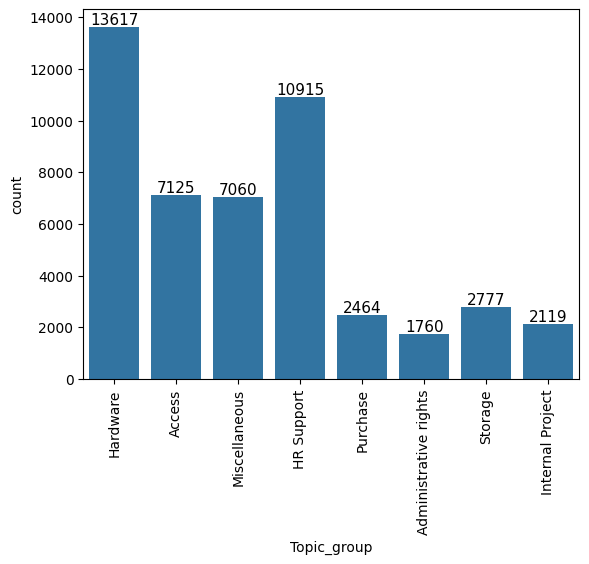

In [15]:
# Make sure you run the cells above first to load the 'data' DataFrame
#sns.countplot(data=data, x='Topic_group')
#plt.xticks(rotation=90)
#plt.show()


ax = sns.countplot(data=data, x='Topic_group')
plt.xticks(rotation=90)

for p in ax.patches:
    ax.annotate(
        int(p.get_height()),
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha="center", va="center",
        size=11, xytext=(0, 5), textcoords="offset points",
    )

plt.show()

# **Data Preprocessing**

In [16]:
dataset = data.copy()

## **Preprocessing the textual column**

In [17]:
# Loading the Porter Stemmer
ps = PorterStemmer()

Text cleaning (lowercasing, stopword removal, punctuation handling)

In [18]:
#stopwords = set(stopwords.words('english'))
custom_stopwords =  { "a", "an", "the", "and", "or", "but", "if", "of", "at",
                     "by", "for", "with", "about", "to", "from", "in", "on", "off", "over", "under", "again",
                     "then", "once", "here", "there", "when", "where", "why", "how", "all", "any", "both", "each", "few",
                     "more", "most", "other", "some", "such", "own", "same", "so", "than", "too", "very", "can", "just", "should",
                     "now", "i", "me", "my", "myself", "we", "our", "you", "your", "he", "him", "his", "she", "her", "it", "its",
                     "they", "them", "their", "what", "which", "who", "this", "that", "these", "those", "am", "is", "are", "was",
                     "were", "be", "been", "being", "have", "has", "had", "do", "does", "did", "will", "would", "could", "as",
                     "into", "through", "during", "before", "after", "hi", "hello", "dear", "regards", "thanks", "thank", "please",
                     "kindly", "team", "support", "sir", "madam","pm", "am", "re", "ext", "en", "ctrl", "alt", "os",
                     "importance", "high", "low", "medium",
                      "sent", "monday", "tuesday", "wednesday", "thursday", "friday",
                      "saturday", "sunday", "january", "february", "march", "april",
                      "may", "june", "july", "august", "september", "october",
                      "november", "december",
                      "mobile", "phone", "best", "good", "kind", }

In [19]:
# Removing English language stopwords
    #text = ' '.join([word for word in words if word not in stopwords.words('english')])


In [20]:
def preprocess_text(text):
    if pd.isna(text):
        return text

    # Convert to lowercase
    text = text.lower()

    # Remove special characters and numbers
    text = re.sub(r'[^A-Za-z\s]', '', text)

    # Remove extra whitespaces
    text = re.sub(r'\s+', ' ', text).strip()

    # Remove custom_stopwords
    words = [word for word in text.split() if word not in custom_stopwords]

    # Applying the Porter Stemmer on every word and joining back into a single string
    text = ' '.join([ps.stem(word) for word in words])

    # Remove consecutively repeated words (e.g. "icon icon" -> "icon")
    text = re.sub(r'\b(\w+)( \1\b)+', r'\1', text, flags=re.IGNORECASE)

    # Remove "sent <day> <month>" timestamp patterns
    text = re.sub(r'\bsent\s+\w+\s+\w+\b', ' ', text, flags=re.IGNORECASE)

    # Remove "importance high/low/medium"
    text = re.sub(r'\bimportance\s+(high|low|medium)\b', ' ', text, flags=re.IGNORECASE)

    # Remove extension references like "ext 1234"
    text = re.sub(r'\bext\s*\d*\b', ' ', text, flags=re.IGNORECASE)

    return text


In [21]:
# preprocessing the textual column
dataset['Article_text_clean'] = dataset['Document'].apply(preprocess_text)

In [22]:
dataset['Article_text_clean'].head()

,Article_text_clean
0,connect icon setup icon per icon engin let detail need lead
1,work experi user work experi user work experi student come next name much appreci durat
2,request meet request meet help follow equip cabl pc cord plug
3,reset password extern account expir day ask help updat password colleagu expir day receiv expir help prolong expir day expir day order chang follow step prerequisit disabl devic credenti close activ connect cabl machin note also follow step detail press delet pop chang item enter format enter newli chosen enter submit display chang machin brows enter format enter gear icon top tight browser window enter newli chosen enter save connect note complet resourc grant connect cabl brows tick want chang log enter format enter log enter newli chosen enter chang client supplier expir touch person commun back encount issu hesit access your
4,mail verif warn got attach address monitor analyst verif warn


In [23]:
data.head()

,Document,Topic_group
0,connection with icon icon dear please setup icon per icon engineers please let other details needed thanks lead,Hardware
1,work experience user work experience user hi work experience student coming next his name much appreciate him duration thank,Access
2,requesting for meeting requesting meeting hi please help follow equipments cable pc cord plug,Hardware
3,reset passwords for external accounts re expire days hi ask help update passwords colleagues thank pm expire days importance high hi received about expiration please kindly help prolongation best regards pm expire days importance high dear expire days order change please follow steps prerequisites disable device credentials close active connected by cable machine note also follow steps detailed press ctrl alt delete same pops change item enter format enter enter newly chosen then re enter again submit displaying has changed os machine browse enter format enter gear icon top tight browser window enter enter newly chosen then re enter again save connected note complete resources granted once connected by cable browse tick want change after logging enter format enter log enter enter newly chosen then re enter again change clients suppliers about expire please touch person then communicate back encounter issues hesitate by accessing yours,Access
4,mail verification warning hi has got attached please addresses best regards monitoring analyst verification warning,Miscellaneous


    * Before removing Stop words
          connection with icon icon dear please setup icon per icon
          engineers please let other details needed thanks lead    


    * After Removing stopwords
          connect icon setup icon per icon engin let detail need lead

------

### **Comparing the two word-by-word:**

**Before**: connection, with, icon, icon, dear, please, setup, icon, per, icon, engineers, please, let, other, details, needed, thanks, lead

**After**: connect, icon, setup, icon, per, icon, engin, let, detail, need, lead

------

### **Words removed as stopwords:**

with

dear

please (removed both times it appeared)

other

thanks

-------

### **Words that look removed but aren’t — they were stemmed, not dropped:**

connection → connect

engineers → engin

details → detail

needed → need

-------

So **custom_stopwords** list for this run effectively contains (at least): with, dear, please, other, thanks.

The repeated icon/icon/icon instances all survived, since they aren’t consecutive duplicates in the original string (other words sit between them),

so remove_repeated_words correctly left them alone — that function only collapses back-to-back repeats like “icon icon”, not repeats scattered through the sentence.

**Convert text into numerical features**

In [24]:
# Word2Vec

# Creating a list of all words in our data
words_list = [item.split(" ") for item in dataset['Article_text_clean'].values]

In [25]:
# Creating an instance of Word2Vec
vec_size = 125
model_W2V = Word2Vec(words_list, vector_size = vec_size, min_count = 3, window=5, workers = 6)

In [26]:
# Checking the size of the vocabulary
print("Length of the vocabulary is", len(list(model_W2V.wv.key_to_index)))

Length of the vocabulary is 4945


In [27]:
# Checking the word embedding of a random word
word = "password"
model_W2V.wv[word]

array([ 8.52769792e-01, -1.56497610e+00,  8.93060565e-01,  7.06087053e-02,
        8.81642580e-01, -1.34956944e+00, -2.28669405e+00,  1.27322960e+00,
       -1.30256191e-01, -8.85933936e-01, -1.27807796e+00, -1.04487824e+00,
       -6.30617023e-01,  1.11597061e+00, -2.07562637e+00,  8.73063624e-01,
       -1.13134019e-01, -4.85233843e-01,  1.84499526e+00,  2.95246387e+00,
       -1.13865364e+00,  1.50804031e+00,  9.86649632e-01, -1.50121546e+00,
       -1.20041633e+00,  1.06373823e+00, -1.80974233e+00, -7.62464032e-02,
       -1.03265309e+00, -6.54538155e-01, -3.36150825e-01, -1.07687470e-02,
       -1.17183852e+00,  1.98276237e-01, -2.14704454e-01, -8.65078568e-01,
        7.72692144e-01, -7.81462789e-01,  3.99840236e-01, -2.09035099e-01,
        4.21102643e-01, -1.87183821e+00,  8.94735515e-01, -7.85428166e-01,
        4.77728099e-01, -2.34307051e+00,  1.41545010e+00,  4.99700755e-01,
        1.09774508e-01, -1.44584608e+00,  1.39007643e-01, -3.89744312e-01,
       -1.90217817e+00,  

In [28]:
# Retrieving the words present in the Word2Vec model's vocabulary
words = list(model_W2V.wv.key_to_index.keys())

# Retrieving word vectors for all the words present in the model's vocabulary
wvs = model_W2V.wv[words].tolist()

# Creating a dictionary of words and their corresponding vectors
word_vector_dict = dict(zip(words, wvs))

In [29]:
def average_vectorizer_Word2Vec(doc):
    # Initializing a feature vector for the sentence
    feature_vector = np.zeros((vec_size,), dtype="float64")

    # Creating a list of words in the sentence that are present in the model vocabulary
    words_in_vocab = [word for word in doc.split() if word in words]

    # adding the vector representations of the words
    for word in words_in_vocab:
        feature_vector += np.array(word_vector_dict[word])

    # Dividing by the number of words to get the average vector
    if len(words_in_vocab) != 0:
        feature_vector /= len(words_in_vocab)

    return feature_vector

In [30]:
# creating a dataframe of the vectorized documents
df_Word2Vec = pd.DataFrame(dataset['Article_text_clean'].apply(average_vectorizer_Word2Vec).tolist(), columns=['Feature '+str(i) for i in range(vec_size)])
df_Word2Vec

,Feature 0,Feature 1,Feature 2,Feature 3,Feature 4,Feature 5,Feature 6,Feature 7,Feature 8,Feature 9,...,Feature 115,Feature 116,Feature 117,Feature 118,Feature 119,Feature 120,Feature 121,Feature 122,Feature 123,Feature 124
0,-0.525563,0.133290,0.691183,-0.517313,0.938665,-0.081223,0.036107,0.387692,-0.257567,0.734822,...,0.299975,-0.552718,-0.358505,-0.237156,-0.377296,-0.434403,0.051784,0.067106,-0.147958,0.665235
1,-0.029392,-0.387160,0.397928,-0.691467,-0.545627,-0.231762,-0.168305,0.380733,-0.057289,0.106171,...,0.072939,0.094170,0.026225,-0.155528,-0.022014,-0.449751,0.667737,-0.056197,0.055403,0.363736
2,-0.848618,-0.282273,-0.139502,0.834076,0.467530,0.541802,0.072736,0.631393,0.426176,0.821607,...,0.250537,0.342250,-0.184599,0.121717,-0.158121,0.446423,0.869148,0.825333,-0.214586,0.630459
3,0.204212,-0.448509,0.427504,-0.561003,0.389721,-0.304438,-0.374418,0.485793,0.142576,0.291097,...,0.019178,0.109753,-0.004573,0.055791,0.079932,0.281815,0.369514,0.026686,0.201299,0.427939
4,0.146659,-0.057252,-0.387415,-0.105996,-0.223876,-0.294001,-0.017024,0.202204,0.216033,0.383874,...,0.488018,0.553948,0.248094,0.480981,0.171852,0.116184,0.299063,0.033534,0.605228,0.074677
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47832,-0.463220,0.035166,0.164498,-0.577140,0.391125,-0.499512,-0.072468,0.199003,0.277322,0.761036,...,-0.121402,-0.149633,-0.184035,-0.044169,0.134089,0.046623,-0.081804,0.037029,0.183374,-0.178118
47833,0.597717,-0.506518,-0.095850,-0.585646,0.266521,-0.239603,-0.218990,-0.274614,0.794382,0.449525,...,-0.355907,0.123566,-0.347288,0.468387,0.167507,-0.514292,-0.452422,-0.055893,0.243708,-0.148441
47834,-0.523633,-0.327817,-0.060068,-0.338762,0.047222,0.372669,-0.277775,0.521666,0.273516,0.141763,...,0.140114,0.383808,0.036166,0.289642,0.078901,-0.145132,0.318828,0.032866,0.370058,0.540383
47835,0.267489,-0.502171,0.348501,-0.408847,0.138525,-0.022053,-0.126007,0.130862,0.343941,0.093689,...,-0.199541,0.186637,0.109727,0.297927,0.119621,0.019942,0.186282,0.262477,0.214411,0.086958


**Train classification models**

In [31]:
le = LabelEncoder()
y = le.fit_transform(dataset['Topic_group'])

label_mapping = dict(zip(le.classes_, le.transform(le.classes_)))
print(label_mapping)


X = df_Word2Vec.values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


rf = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

{'Access': np.int64(0), 'Administrative rights': np.int64(1), 'HR Support': np.int64(2), 'Hardware': np.int64(3), 'Internal Project': np.int64(4), 'Miscellaneous': np.int64(5), 'Purchase': np.int64(6), 'Storage': np.int64(7)}


RandomForestClassifier(class_weight='balanced', n_estimators=200, n_jobs=-1,
                       random_state=42)

### **Evaluating Model Performance on Base line of Random Forest**

In [32]:
y_pred = rf.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)*100
precision = precision_score(y_test, y_pred, average='weighted')*100
recall = recall_score(y_test, y_pred, average='weighted')*100
f1 = f1_score(y_test, y_pred, average='weighted')*100

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

Accuracy:  79.4732
Precision: 81.2932
Recall:    79.4732
F1 Score:  79.3409


In [33]:
cm = confusion_matrix(y_test, y_pred)


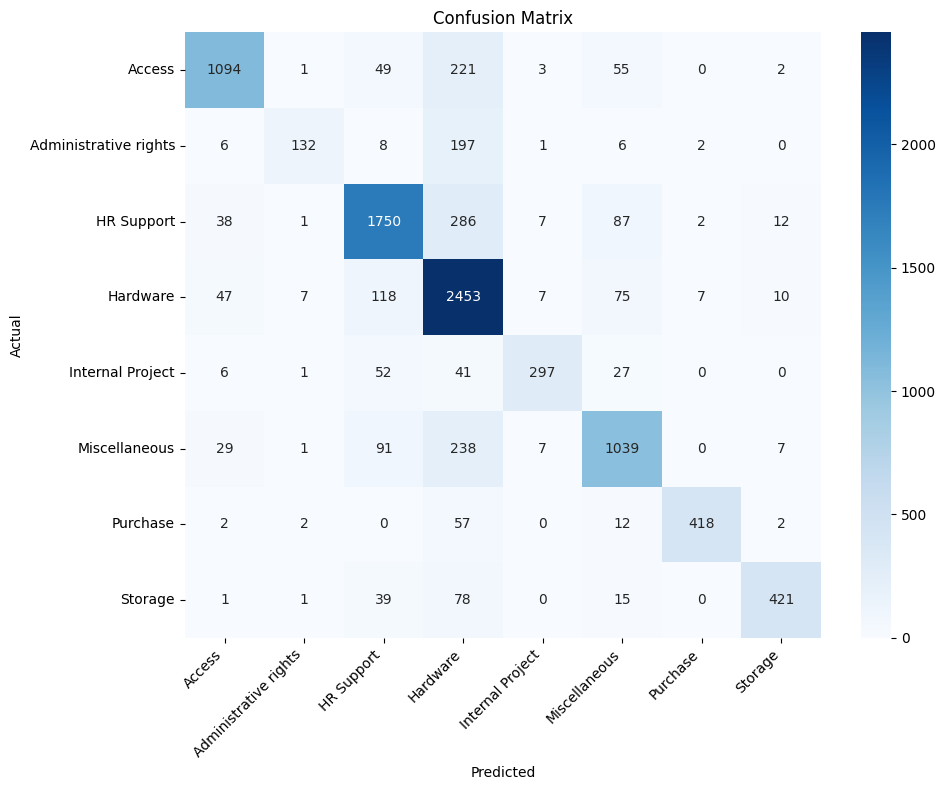

In [34]:
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


### **Trying undersampling method**

In [35]:
!pip install imbalanced-learn

In [36]:
from imblearn.ensemble import BalancedBaggingClassifier
from sklearn.tree import DecisionTreeClassifier

bbc = BalancedBaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=200,
    sampling_strategy='auto',   # undersamples majority classes to match minority count per bootstrap
    random_state=42,
    n_jobs=-1
)
bbc.fit(X_train, y_train)

BalancedBaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=200,
                          n_jobs=-1, random_state=42)

In [37]:
y_pred_bbc = bbc.predict(X_test)

accuracy_bbc = accuracy_score(y_test, y_pred_bbc)
precision_bbc = precision_score(y_test, y_pred_bbc, average='weighted')
recall_bbc = recall_score(y_test, y_pred_bbc, average='weighted')
f1_bbc = f1_score(y_test, y_pred_bbc, average='weighted')

print(f"Accuracy:  {accuracy_bbc:.4f}")
print(f"Precision: {precision_bbc:.4f}")
print(f"Recall:    {recall_bbc:.4f}")
print(f"F1 Score:  {f1_bbc:.4f}")

print(classification_report(y_test, y_pred_bbc, target_names=le.classes_))

Accuracy:  0.7646
Precision: 0.7754
Recall:    0.7646
F1 Score:  0.7668
                       precision    recall  f1-score   support

               Access       0.78      0.80      0.79      1425
Administrative rights       0.48      0.71      0.57       352
           HR Support       0.86      0.74      0.79      2183
             Hardware       0.78      0.72      0.75      2724
     Internal Project       0.70      0.84      0.77       424
        Miscellaneous       0.69      0.78      0.73      1412
             Purchase       0.90      0.88      0.89       493
              Storage       0.73      0.86      0.79       555

             accuracy                           0.76      9568
            macro avg       0.74      0.79      0.76      9568
         weighted avg       0.78      0.76      0.77      9568



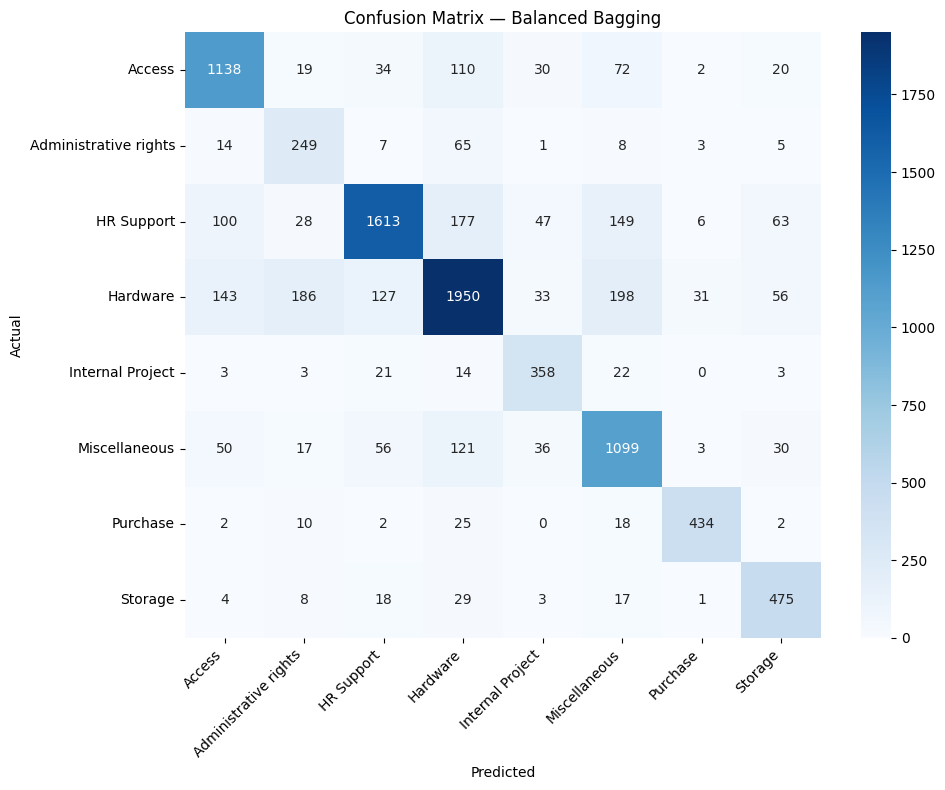

In [38]:
cm_bbc = confusion_matrix(y_test, y_pred_bbc)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_bbc, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix — Balanced Bagging')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### **Trying Oversample method**

In [39]:
import pandas as pd
print(pd.Series(y_train).value_counts().sort_index())


0     5700
1     1408
2     8732
3    10893
4     1695
5     5648
6     1971
7     2222
Name: count, dtype: int64


In [40]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Before SMOTE:", pd.Series(y_train).value_counts().sort_index().to_dict())
print("After SMOTE: ", pd.Series(y_train_smote).value_counts().sort_index().to_dict())

Before SMOTE: {0: 5700, 1: 1408, 2: 8732, 3: 10893, 4: 1695, 5: 5648, 6: 1971, 7: 2222}
After SMOTE:  {0: 10893, 1: 10893, 2: 10893, 3: 10893, 4: 10893, 5: 10893, 6: 10893, 7: 10893}


In [41]:
rf_smote = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)
rf_smote.fit(X_train_smote, y_train_smote)

RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)

In [42]:
y_pred_smote = rf_smote.predict(X_test)

print("Accuracy: ", accuracy_score(y_test, y_pred_smote))
print("Precision: ", precision_score(y_test, y_pred_smote, average='weighted'))
print("Recall: ", recall_score(y_test, y_pred_smote, average='weighted'))
print("F1 Score: ", f1_score(y_test, y_pred_smote, average='weighted'))
print(classification_report(y_test, y_pred_smote, target_names=le.classes_))




Accuracy:  0.8108277591973244
Precision:  0.8138616938326019
Recall:  0.8108277591973244
F1 Score:  0.8115309730274517
                       precision    recall  f1-score   support

               Access       0.86      0.83      0.84      1425
Administrative rights       0.66      0.64      0.65       352
           HR Support       0.87      0.80      0.83      2183
             Hardware       0.77      0.81      0.79      2724
     Internal Project       0.81      0.84      0.83       424
        Miscellaneous       0.75      0.80      0.77      1412
             Purchase       0.94      0.88      0.91       493
              Storage       0.82      0.85      0.83       555

             accuracy                           0.81      9568
            macro avg       0.81      0.81      0.81      9568
         weighted avg       0.81      0.81      0.81      9568



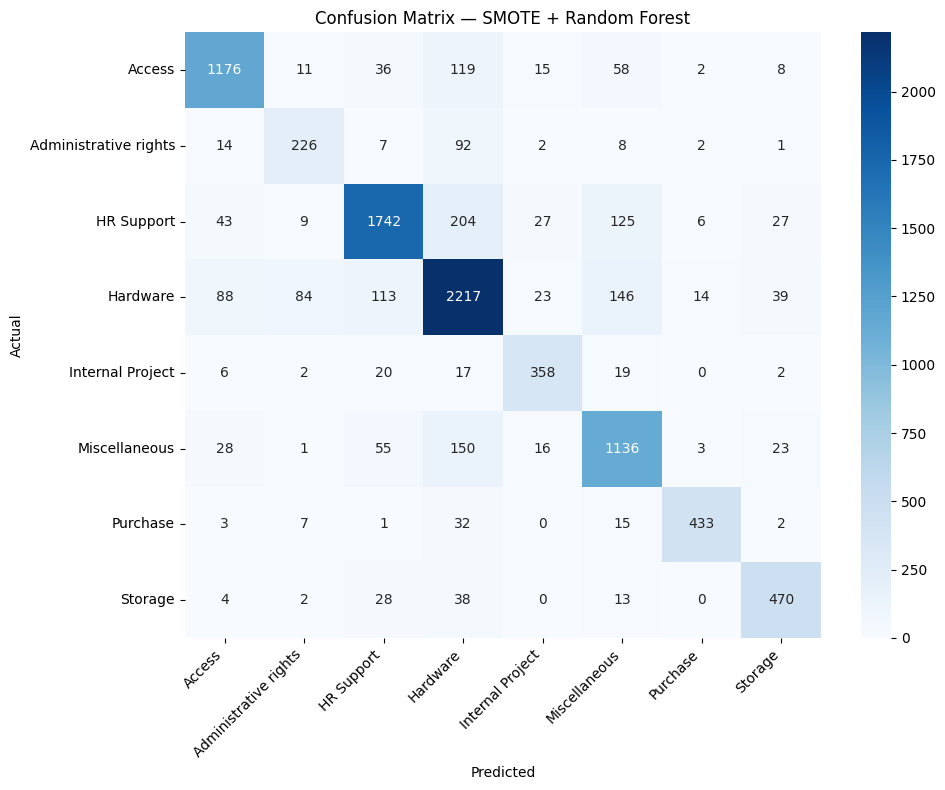

In [43]:
cm_smote = confusion_matrix(y_test, y_pred_smote)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_smote, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix — SMOTE + Random Forest')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# **Comparing Performence of Every model build**

In [44]:
# Build comparison dataframe
comparison = pd.DataFrame({
    'Model': ['Random Forest (baseline)', 'Random Forest + Undersampling', 'Random Forest + SMOTE (oversample)'],
    'Accuracy': [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_bbc),
        accuracy_score(y_test, y_pred_smote)
    ],
    'Precision (weighted)': [
        precision_score(y_test, y_pred, average='weighted'),
        precision_score(y_test, y_pred_bbc, average='weighted'),
        precision_score(y_test, y_pred_smote, average='weighted')
    ],
    'Recall (weighted)': [
        recall_score(y_test, y_pred, average='weighted'),
        recall_score(y_test, y_pred_bbc, average='weighted'),
        recall_score(y_test, y_pred_smote, average='weighted')
    ],
    'F1 Score (weighted)': [
        f1_score(y_test, y_pred, average='weighted'),
        f1_score(y_test, y_pred_bbc, average='weighted'),
        f1_score(y_test, y_pred_smote, average='weighted')
    ]
})

print(comparison.round(4).to_string(index=False))

                             Model  Accuracy  Precision (weighted)  Recall (weighted)  F1 Score (weighted)
          Random Forest (baseline)    0.7947                0.8129             0.7947               0.7934
     Random Forest + Undersampling    0.7646                0.7754             0.7646               0.7668
Random Forest + SMOTE (oversample)    0.8108                0.8139             0.8108               0.8115


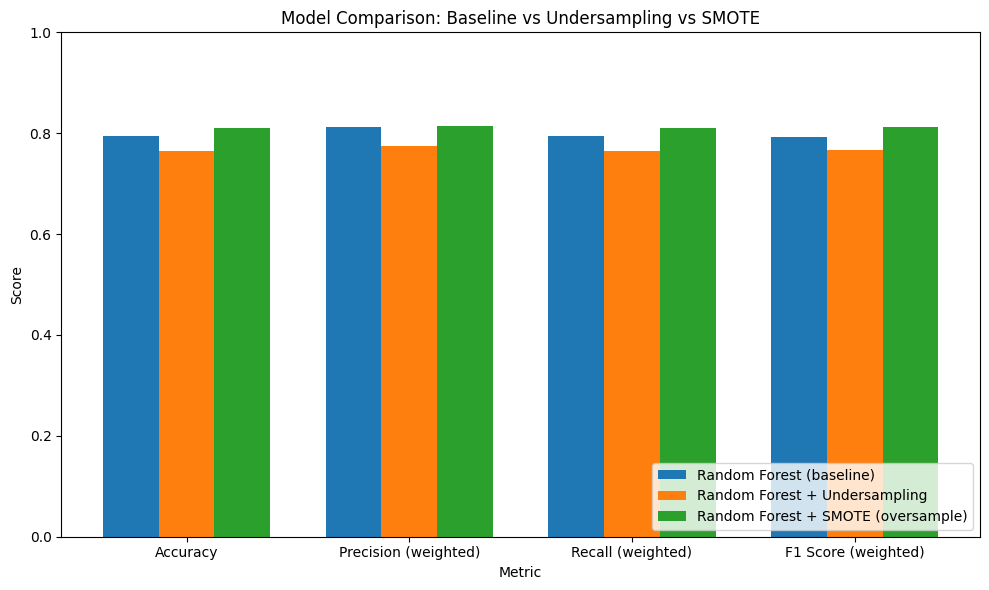

In [45]:
metrics = ['Accuracy', 'Precision (weighted)', 'Recall (weighted)', 'F1 Score (weighted)']
x = np.arange(len(metrics))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))
for i, model in enumerate(comparison['Model']):
    values = comparison.loc[comparison['Model'] == model, metrics].values.flatten()
    ax.bar(x + i*width, values, width, label=model)

ax.set_xlabel('Metric')
ax.set_ylabel('Score')
ax.set_title('Model Comparison: Baseline vs Undersampling vs SMOTE')
ax.set_xticks(x + width)
ax.set_xticklabels(metrics)
ax.legend(loc='lower right')
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

In [46]:
from sklearn.metrics import recall_score as rs

class_recall = pd.DataFrame({
    'Class': le.classes_,
    'Baseline RF': rs(y_test, y_pred, average=None),
    'Undersampling': rs(y_test, y_pred_bbc, average=None),
    'SMOTE': rs(y_test, y_pred_smote, average=None)
})

print(class_recall.round(3).to_string(index=False))

                Class  Baseline RF  Undersampling  SMOTE
               Access        0.768          0.799  0.825
Administrative rights        0.375          0.707  0.642
           HR Support        0.802          0.739  0.798
             Hardware        0.901          0.716  0.814
     Internal Project        0.700          0.844  0.844
        Miscellaneous        0.736          0.778  0.805
             Purchase        0.848          0.880  0.878
              Storage        0.759          0.856  0.847


In [51]:
import os
os.makedirs("Support_Ticket_Classification", exist_ok=True)

# Define the file path to load the uploaded serialized model
model_path = "Support_Ticket_Classification/Ticket_Classification_machine_learning_model_v1_0.joblib"

#saved_model = joblib.load(model_path)

# Confirm the model is loaded
#print("Model loaded successfully.")

# Save the best trained model pipeline using joblib
joblib.dump(rf_smote, model_path)

print(f"Model saved successfully at {model_path}")

saved_model = joblib.load(model_path)

# Confirm the model is loaded
print("Model loaded successfully.")

Model saved successfully at Support_Ticket_Classification/Ticket_Classification_machine_learning_model_v1_0.joblib
Model loaded successfully.


# **Random Forest + SMOTE (oversample) is choosed as best model**

test ticket Questions on each label if you want to test the model:

        Questions
        I need a second monitor for my desk, please provide one.
        My laptop keyboard stopped working, please replace it.
        Request for an extension cord and a new mouse.

        Predicted Output classification should be:
        Hardware

-----
        Questions
        Please reject my timesheet, I need to resubmit it because I was on leave.
        New starter joining on Monday, please set up their account.
        Leaver ticket: please process the exit formalities for an employee.

        Predicted Output classification should be:
        HR Support

-----
        Questions
        My access card is not working, please check and reactivate it.
        Please reset my password, I am locked out of my account.
        I need a license for Visual Studio for automation training.

        Predicted Output classification should be:
        Access

-----
        Questions
        Expense report is not showing for manager approval in Oracle.
        Feedback survey rating is not being recorded for the ticket.
        Please update the distribution list and add a new address.

        Predicted Output classification should be:
        Miscellaneous

-----
        Questions
        My mailbox is almost full, please increase the mailbox size.
        I cannot access the shared network folder, please give me permission.
        Please restore the file from the shared drive path.

        Predicted Output classification should be:
        Storage

-----
        Questions
        Please create a PO for the new laptop bags and perform the receipt.
        New purchase order for screen protectors, please log the allocation.
        Update the PO report to add the location column.

        Predicted Output classification should be:
        Purchase

------
        Questions
        Please create a new project code for the signed contract.
        New project setup in Oracle PAS, please create the code.
        Replace the project code and allocate it to the new team members.

        Predicted Output classification should be:
        Internal Project

------
        Questions
        Outlook is not starting, please help me fix it.
        I need admin rights to install software on my machine.
        Windows upgrade is failing with an error, please assist.

        Predicted Output classification should be:
        Administrative rights

In [52]:
def testing(ticket):
    # Step 1: clean it the same way as training data
    cleaned = preprocess_text(ticket)

    # Step 2: convert to the same 125-dim averaged Word2Vec vector
    vector = average_vectorizer_Word2Vec(cleaned)

    # Step 3: reshape to 2D since predict expects a matrix
    vector = vector.reshape(1, -1)

    # Step 4: predict and decode the label
    pred_encoded = rf_smote.predict(vector)
    pred_label = le.inverse_transform(pred_encoded)

    return pred_label[0]

In [53]:
new_ticket = input("Enter the ticket description: ")

result = testing(new_ticket)
print("Predicted category:", result)

Enter the ticket description: Replace the project code and allocate it to the new team members.
Predicted category: Internal Project


# **Explain how this system improves support operations**

1. Faster first response. Tickets reach the right queue immediately instead of waiting for manual triage. For a team handling hundreds or thousands of tickets a day, this removes the sorting step that delays every ticket behind it.

2. Less time spent sorting, more time solving. Agents no longer read and route tickets by hand. That effort goes to resolution.

3. Consistent categorization. Human triage varies between people and shifts. The model applies the same logic every time, which makes reporting on ticket volume by category trustworthy.

4. Better workload planning. Reliable categories show which areas (e.g., Hardware at ~28% of tickets, HR Support at ~23%) drive demand, supporting staffing and training decisions.

5. Reduced backlog and misrouting. Correct routing avoids tickets bouncing between teams, a common source of delay and customer frustration.